PROJECT TITILE - **CREDIT ANALYSIS BY SCHEDULED COMMERCIAL BANK**

# Project Goal:

- **Exploratory Data Analysis (EDA)** with real-world banking credit data
- **Data cleaning** (duplicates, missing values, outliers, inconsistent categories)
- **Data visualization** with matplotlib and seaborn
- **Economic insight generation** on regional, sectoral, and rural-urban credit disparity

## Dataset Information

| Attribute | Value |
|---|---|
| Source | Reserve Bank of India (RBI), via India Data Portal |
| Source Link | https://indiadataportal.com/p/reserve-bank-of-india/r/rbi-groupwise_credit_by_scbs-dt-yr-vvi |
| Original Source | RBI Basic Statistical Return (BSR)-1 |
| Original Records | ~22,33,408 (district-bank-occupation level, 2010–2026) |
| Sampled Records (used in this project) | 50,000 |
| Features | 14 columns |
| Time Period | 2010–2026 |

Note on sampling: The original dataset contains ~22.3 lakh records at the district-bank-occupation level. A random sample of 50,000 rows was drawn for computational efficiency, verified to retain representation across all years, regions, states, and categories.

## Dataset Columns

- **Identifiers**: id, year
- **Geography**: region, state_name, state_code, district_name, district_code, population_group
- **Bank Info**: bank_group
- **Loan Purpose**: occupation_group, occupation_sub_group
- **Credit Metrics**: no_of_accounts, credit_limit, amount_outstanding

## Objectives

1. Analyze the growth trend of bank credit (sanctioned and outstanding) across India from 2010 to 2026.
2. Examine the disparity in credit access between rural, semi-urban, urban, and metropolitan areas.
3. Study the regional and state-wise distribution of bank credit across India.
4. Determine how credit is allocated across economic sectors and how this has changed over time.
5. Evaluate the market share and credit utilization of different bank groups.

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [ ]:
df = pd.read_csv("/content/credit_analysis_by_scheduled commercial bank__.csv")

## Data Cleaning Process

1. **Understanding the data** — Getting an overview of the dataset's size, column types, and basic statistics.
2. **Removing duplicates** — Dropping exact duplicate rows.
3. **Handling missing values** — Filling or labeling missing data instead of dropping rows.
4. **Fixing inconsistent data** — Standardizing spelling and fixing logical errors.
5. **Handling outliers** — Identifying extreme values with the IQR method and treating them appropriately.

In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 50026 entries, 0 to 50025
Data columns (total 14 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   id                    50026 non-null  int64  
 1   year                  50026 non-null  int64  
 2   region                50026 non-null  object 
 3   state_name            50026 non-null  object 
 4   state_code            50026 non-null  int64  
 5   district_name         49982 non-null  object 
 6   district_code         50026 non-null  int64  
 7   population_group      50026 non-null  object 
 8   bank_group            49988 non-null  object 
 9   occupation_group      50026 non-null  object 
 10  occupation_sub_group  44993 non-null  object 
 11  no_of_accounts        50026 non-null  float64
 12  credit_limit          49976 non-null  float64
 13  amount_outstanding    50026 non-null  float64
dtypes: float64(3), int64(4), object(7)
memory usage: 5.3+ MB


In [ ]:
df.shape

(50026, 14)

In [ ]:
df.describe()

,id,year,state_code,district_code,no_of_accounts,credit_limit,amount_outstanding
count,50026.000000,50026.000000,50026.000000,50026.000000,5.002600e+04,49976.000000,50026.000000
mean,24999.833547,2019.161016,18.705693,353.574521,1.685433e+03,113.200675,73.820109
std,14434.198627,4.810753,9.988569,201.425816,1.807296e+04,1465.859978,936.738446
min,1.000000,2010.000000,1.000000,1.000000,0.000000e+00,0.000000,0.000000
25%,12500.250000,2015.000000,9.000000,166.000000,6.000000e+00,0.210000,0.140000
50%,25000.500000,2020.000000,20.000000,374.000000,3.400000e+01,1.720000,1.240000
75%,37498.750000,2023.000000,27.000000,522.000000,2.800000e+02,14.670000,10.437500
max,50000.000000,2026.000000,38.000000,793.000000,2.825060e+06,103115.580000,87701.040000


In [ ]:
df.columns

Index(['id', 'year', 'region', 'state_name', 'state_code', 'district_name',
       'district_code', 'population_group', 'bank_group', 'occupation_group',
       'occupation_sub_group', 'no_of_accounts', 'credit_limit',
       'amount_outstanding'],
      dtype='object')

In [ ]:
df.head()

,id,year,region,state_name,state_code,district_name,district_code,population_group,bank_group,occupation_group,occupation_sub_group,no_of_accounts,credit_limit,amount_outstanding
0,1,2024,Southern Region,Tamil Nadu,33,Mayiladuthurai,735,Semi Urban,Private Sector Banks,Agriculture,Indirect Finance,154.0,10.14,8.79
1,2,2022,Southern Region,Tamil Nadu,33,Pudukkottai,582,Urban,Foreign Banks,Personal Loans,Housing,5.0,0.52,0.38
2,3,2025,Northern Region,Haryana,6,Gurugram,62,Rural,Private Sector Banks,Industry,Engineering,51.0,77.70,68.94
3,4,2020,Eastern Region,Jharkhand,20,Khunti,606,Semi-Urban,Private Sector Banks,Industry,Chemicals & Chemical Products,1.0,0.00,0.00
4,5,2024,Northern Region,Punjab,3,Pathankot,662,Rural,Public Sector Banks,Industry,Textiles,39.0,0.75,0.54


In [ ]:
df.tail()

,id,year,region,state_name,state_code,district_name,district_code,population_group,bank_group,occupation_group,occupation_sub_group,no_of_accounts,credit_limit,amount_outstanding
50021,49996,2022,Southern Region,Kerala,32,Pathanamthitta,564,Semi-Urban,Foreign Banks,Personal Loans,Personal Credit Cards,158.0,3.16,0.45
50022,49997,2015,Northern Region,Haryana,6,Ambala,58,Urban,Private Sector Banks,Industry,Manufacture Of Cement & Cement Products,2.0,0.18,0.11
50023,49998,2017,Central Region,Uttar Pradesh,9,Hapur,661,Urban,Private Sector Banks,Agriculture,Direct Finance,2184.0,21.45,18.48
50024,49999,2024,Western Region,Maharashtra,27,Dharashiv,488,Semi Urban,Small Finance Banks,Agriculture,Indirect Finance,18.0,0.27,0.19
50025,50000,2025,Southern Region,Telangana,36,Nalgonda,514,Urban,Private Sector Banks,Professional And Other Services,Professional Services,182.0,40.99,29.66


In [ ]:
df.duplicated()

,0
0,False
1,False
2,False
3,False
4,False
...,...
50021,False
50022,False
50023,False
50024,False


In [ ]:
df.isnull().sum()

,0
id,0
year,0
region,0
state_name,0
state_code,0
district_name,44
district_code,0
population_group,0
bank_group,38
occupation_group,0


In [ ]:
df.duplicated().sum()

np.int64(26)

In [ ]:
print(df.nunique())

id                      50000
year                       17
region                      6
state_name                 36
state_code                 36
district_name             764
district_code             767
population_group            5
bank_group                  8
occupation_group            8
occupation_sub_group       32
no_of_accounts           5839
credit_limit            10288
amount_outstanding       9187
dtype: int64


**REMOVING DUPLICATES**

*Checking the dataset for duplicate rows with `df.duplicated().sum()`.
26 duplicates were found and removed using `df.drop_duplicates()`.*

In [ ]:
df.duplicated().sum()

np.int64(26)

In [ ]:
df = df.drop_duplicates()

In [ ]:
df.duplicated().sum()

np.int64(0)

In [ ]:
df.shape

(50000, 14)

**REMOVING MISSING VALUES**

*Checked for missing values using `isnull().sum()`*

Found missing values in 4 columns:
- `district_name` — 44 missing
- `bank_group` — 38 missing
- `occupation_sub_group` — 5032 missing
- `credit_limit` — 50 missing

Filled them as follows:
- `occupation_sub_group` — filled with "Not Applicable" (some occupation group
     have no sub-category)
- `bank_group` — filled with "Not Specified"
- `district_name` — filled with "Unknown"
- `credit_limit` — filled with the median value as it is a numerical  column

In [ ]:
print(df.isnull().sum())

id                         0
year                       0
region                     0
state_name                 0
state_code                 0
district_name             44
district_code              0
population_group           0
bank_group                38
occupation_group           0
occupation_sub_group    5032
no_of_accounts             0
credit_limit              50
amount_outstanding         0
dtype: int64


In [ ]:
df

,id,year,region,state_name,state_code,district_name,district_code,population_group,bank_group,occupation_group,occupation_sub_group,no_of_accounts,credit_limit,amount_outstanding
0,1,2024,Southern Region,Tamil Nadu,33,Mayiladuthurai,735,Semi Urban,Private Sector Banks,Agriculture,Indirect Finance,154.0,10.14,8.79
1,2,2022,Southern Region,Tamil Nadu,33,Pudukkottai,582,Urban,Foreign Banks,Personal Loans,Housing,5.0,0.52,0.38
2,3,2025,Northern Region,Haryana,6,Gurugram,62,Rural,Private Sector Banks,Industry,Engineering,51.0,77.70,68.94
3,4,2020,Eastern Region,Jharkhand,20,Khunti,606,Semi-Urban,Private Sector Banks,Industry,Chemicals & Chemical Products,1.0,0.00,0.00
4,5,2024,Northern Region,Punjab,3,Pathankot,662,Rural,Public Sector Banks,Industry,Textiles,39.0,0.75,0.54
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
50021,49996,2022,Southern Region,Kerala,32,Pathanamthitta,564,Semi-Urban,Foreign Banks,Personal Loans,Personal Credit Cards,158.0,3.16,0.45
50022,49997,2015,Northern Region,Haryana,6,Ambala,58,Urban,Private Sector Banks,Industry,Manufacture Of Cement & Cement Products,2.0,0.18,0.11
50023,49998,2017,Central Region,Uttar Pradesh,9,Hapur,661,Urban,Private Sector Banks,Agriculture,Direct Finance,2184.0,21.45,18.48
50024,49999,2024,Western Region,Maharashtra,27,Dharashiv,488,Semi Urban,Small Finance Banks,Agriculture,Indirect Finance,18.0,0.27,0.19


In [ ]:
df["district_name"] = df["district_name"].fillna("Unknown")

In [ ]:
df["bank_group"] = df["bank_group"].fillna("Not Specified")

In [ ]:
df["occupation_sub_group"] = df["occupation_sub_group"].fillna("Not Applicable")

In [ ]:
df["credit_limit"] = df["credit_limit"].fillna(df["credit_limit"].median())

In [ ]:
print(df.isnull().sum())

id                      0
year                    0
region                  0
state_name              0
state_code              0
district_name           0
district_code           0
population_group        0
bank_group              0
occupation_group        0
occupation_sub_group    0
no_of_accounts          0
credit_limit            0
amount_outstanding      0
dtype: int64


**Fixing Inconsistent Data**

- Checked all categorical columns using `.unique()` for spelling issues.
- Fixed `bank_group`: "Small Finance Bank" and "Small Finance Banks" standardized using `replace()`
- Fixed `population_group`: "Semi Urban" and "Semi-Urban" standardized to one spelling using `replace()`.
- Investigated `district_name` vs `district_code` mismatch — found 3 names (Pratapgarh,
  Bilaspur, Hamirpur) each belong to 2 different states/districts.
- Checked logical consistency: `amount_outstanding` should not exceed `credit_limit`.

 -- Checked `amount_outstanding` vs `credit_limit` and found 1,070 rows where the outstanding amount is higher than the limit as the exact reason is unknown  the values were kept unchanged.

In [ ]:
print(df["population_group"].unique())

['Semi Urban' 'Urban' 'Rural' 'Semi-Urban' 'Metropolitan']


In [ ]:
print(df["region"].unique())

['Southern Region' 'Northern Region' 'Eastern Region' 'Western Region'
 'Central Region' 'North Eastern Region']


In [ ]:
print(df["state_name"].unique())

['Tamil Nadu' 'Haryana' 'Jharkhand' 'Punjab' 'Gujarat' 'Uttar Pradesh'
 'Odisha' 'Maharashtra' 'Himachal Pradesh' 'Assam' 'Jammu And Kashmir'
 'Tripura' 'Bihar' 'Karnataka' 'Rajasthan' 'Madhya Pradesh' 'West Bengal'
 'Kerala' 'Chhattisgarh' 'Telangana' 'Uttarakhand' 'Nagaland' 'Meghalaya'
 'Delhi' 'Manipur' 'Andhra Pradesh' 'Chandigarh' 'Arunachal Pradesh'
 'The Dadra And Nagar Haveli And Daman And Diu' 'Sikkim'
 'Andaman And Nicobar Islands' 'Mizoram' 'Ladakh' 'Puducherry' 'Goa'
 'Lakshadweep']


In [ ]:
print(df["bank_group"].unique())

['Private Sector Banks' 'Foreign Banks' 'Public Sector Banks'
 'Regional Rural Banks' 'Small Finance Bank' 'Small Finance Banks'
 'Individual Regional Rural Banks' 'Local Area Banks' 'Not Specified']


In [ ]:
print(df["occupation_group"].unique())

['Agriculture' 'Personal Loans' 'Industry' 'Transport Operators'
 'Professional And Other Services' 'Trade' 'All Others' 'Finance']


In [ ]:
print(df["occupation_sub_group"].unique())

['Indirect Finance' 'Housing' 'Engineering'
 'Chemicals & Chemical Products' 'Textiles' 'Mining & Quarrying'
 'Direct Finance' 'Others' 'Not Applicable' 'Recreation Services'
 'Retail Trade' 'Manufacture Of Cement & Cement Products'
 'Personal Credit Cards' 'Basic Metals & Metal Products'
 'Food Manufacturing & Processing' 'Tourism, Hotel & Restaurants'
 'Professional Services' 'Education' 'Leather & Leather Products'
 'It And Telecommunications' 'Paper, Paper Products & Printing'
 'Wholesale Trade' 'Woods And Wood Products' 'Construction'
 'Beverage & Tobacco' 'Gems And Jewellery' 'Other Industries'
 'Petroleum, Coal Products & Nuclear Fuels' 'Vehicles' 'Consumer Durables'
 'Rubber & Plastic Products'
 'Vehicles,Vehicle Parts & Transport Equipments'
 'Electricity, Gas & Water']


In [ ]:
df["population_group"] = df["population_group"].replace("Semi Urban", "Semi-Urban")

In [ ]:
print(df["population_group"].unique())

['Semi-Urban' 'Urban' 'Rural' 'Metropolitan']


In [ ]:
df["bank_group"] = df["bank_group"].replace("Small Finance Bank", "Small Finance Banks")

In [ ]:
print(df["bank_group"].unique())

['Private Sector Banks' 'Foreign Banks' 'Public Sector Banks'
 'Regional Rural Banks' 'Small Finance Banks'
 'Individual Regional Rural Banks' 'Local Area Banks' 'Not Specified']


In [ ]:
print(df["district_name"].unique())

['Mayiladuthurai' 'Pudukkottai' 'Gurugram' 'Khunti' 'Pathankot' 'Vadodara'
 'Gorakhpur' 'Nayagada' 'Pune' 'Shimla' 'Basti' 'Nalbari' 'Kanniyakumari'
 'Bareilly' 'Hisar' 'Ganderbal' 'Khowai' 'Budaun' 'Purnia' 'Ballari'
 'Shopian' 'Sirohi' 'Wardha' 'Chhindwara' 'Bandipora' 'Supaul' 'Nadia'
 'Rajkot' 'Mysuru' 'Ernakulam' 'Solan' 'Bhind' 'Gandhinagar' 'Damoh'
 'Gwalior' 'Chandrapur' 'Bilaspur' 'Nalgonda' 'Anuppur' 'Kalimpong'
 'Mirzapur' 'Chengalpattu' 'Kushinagar' 'Mandya' 'Kodagu' 'Murshidabad'
 'Yamunanagar' 'Sonitpur' 'Virudhunagar' 'Patan' 'Panch Mahals' 'Jodhpur'
 'Darjeeling' 'Agra' 'Buldhana' 'Dhalai' 'Haridwar' 'Tenkasi'
 'S.A.S Nagar' 'Alipurduar' 'Haveri' 'Kalaburagi' 'Gadchiroli' 'Jehanabad'
 'Purba Bardhaman' 'Samba' 'Pulwama' 'Sawai Madhopur' 'Gopalganj'
 'Neemuch' 'Kapurthala' 'Surendranagar' 'Tirunelveli' 'Jind' 'Sonipat'
 'Dimapur' 'Dahod' 'East Khasi Hills' 'Khordha' 'Patiala' 'Deoria' 'East'
 'Kaushambi' 'Kishanganj' 'Thoubal' 'Nabarangpur' 'Sindhudurg' 'Prakasam'
 'Tiru

In [ ]:
df["amount_outstanding"].gt(df["credit_limit"]).sum()

np.int64(1070)

In [ ]:
print(df["district_name"].nunique())
print(df["district_code"].nunique())

765
767


In [ ]:
print(df.groupby("district_name")["district_code"].nunique().sort_values(ascending=False).head())

district_name
Unknown             43
Pratapgarh           2
Bilaspur             2
Hamirpur             2
North Garo Hills     1
Name: district_code, dtype: int64


In [ ]:
print(df[df["district_name"]=="Pratapgarh"][["state_name","district_name","district_code"]].drop_duplicates())

        state_name district_name  district_code
801  Uttar Pradesh    Pratapgarh            174
875      Rajasthan    Pratapgarh            629


In [ ]:
print(df[df["district_name"]=="Bilaspur"][["state_name","district_name","district_code"]].drop_duplicates())

           state_name district_name  district_code
36       Chhattisgarh      Bilaspur            375
111  Himachal Pradesh      Bilaspur             15


In [ ]:
print(df[df["district_name"]=="Hamirpur"][["state_name","district_name","district_code"]].drop_duplicates())

            state_name district_name  district_code
412   Himachal Pradesh      Hamirpur             17
1201     Uttar Pradesh      Hamirpur            149


**Detecting and Handling Outliers**

Used the IQR method to detect outliers in the 3 numeric columns.

- `amount_outstanding`: found 8,294 outliers. Investigated the top values — found they
  belong to major metro districts (Delhi, Hyderabad, Pune, Mumbai, Bengaluru urban ,Chennai)
- `no_of_accounts`: found 8,507 outliers.
- `credit_limit`: found 8,246 outliers.
-  Kept the values unchanged, since they represent real high-credit metro  districts relevant to this project's analysis.

In [ ]:
Q1 = df["amount_outstanding"].quantile(0.25)
Q3 = df["amount_outstanding"].quantile(0.75)

IQR = Q3 - Q1

lower = Q1 - 1.5 * IQR
upper = Q3 + 1.5 * IQR

outliers = df[
    (df["amount_outstanding"] < lower) |
    (df["amount_outstanding"] > upper)
]

print("Number of outliers:", len(outliers))

Number of outliers: 8294


In [ ]:
print(df.sort_values("amount_outstanding", ascending=False)[["state_name","district_name","amount_outstanding"]].head(5))

        state_name district_name  amount_outstanding
23522        Delhi     New Delhi            87701.04
28794    Telangana     Hyderabad            58603.74
36781  Maharashtra          Pune            49371.45
21204  Maharashtra        Mumbai            42539.08
45282      Haryana       Unknown            41124.36


In [ ]:
Q1 = df["no_of_accounts"].quantile(0.25)
Q3 = df["no_of_accounts"].quantile(0.75)

IQR = Q3 - Q1

lower = Q1 - 1.5 * IQR
upper = Q3 + 1.5 * IQR

outliers = df[
    (df["no_of_accounts"] < lower) |
    (df["no_of_accounts"] > upper)
]

print("Number of outliers:", len(outliers))

Number of outliers: 8507


In [ ]:
print(df.sort_values("no_of_accounts", ascending=False)[["state_name","district_name","no_of_accounts"]].head(5))

        state_name    district_name  no_of_accounts
30627    Karnataka  Bengaluru Urban       2825060.0
2053         Delhi        New Delhi        830366.0
35879   Tamil Nadu          Chennai        801225.0
14197  Maharashtra           Mumbai        774382.0
47217    Telangana        Hyderabad        701507.0


In [ ]:
Q1 = df["credit_limit"].quantile(0.25)
Q3 = df["credit_limit"].quantile(0.75)

IQR = Q3 - Q1

lower = Q1 - 1.5 * IQR
upper = Q3 + 1.5 * IQR

outliers = df[
    (df["credit_limit"] < lower) |
    (df["credit_limit"] > upper)
]

print("Number of outliers:", len(outliers))

Number of outliers: 8246


In [ ]:
print(df.sort_values("credit_limit", ascending=False)[["state_name","district_name","credit_limit"]].head(5))

        state_name district_name  credit_limit
19148  Maharashtra        Mumbai     103115.58
23522        Delhi     New Delhi      99939.70
21204  Maharashtra        Mumbai      94864.99
28794    Telangana     Hyderabad      76329.84
36781  Maharashtra          Pune      69402.43


**Fixing Data Types**

Checked data types using `df.dtypes`. Found `no_of_accounts` as `float64`,
converted it to `int64` using `.astype(int)` since it represents a count.

In [ ]:
print(df.dtypes)

id                        int64
year                      int64
region                   object
state_name               object
state_code                int64
district_name            object
district_code             int64
population_group         object
bank_group               object
occupation_group         object
occupation_sub_group     object
no_of_accounts          float64
credit_limit            float64
amount_outstanding      float64
dtype: object


In [ ]:
df['no_of_accounts'] = df['no_of_accounts'].astype(int)

In [ ]:
print(df['no_of_accounts'].dtype)

int64


**EDA**
1. **Overview:** Checked the shape, structure and summary statistics of the data using `shape`, `head`,`info()` and `describe()`.
2. **Categorical columns:** Counted the records in each region, bank group and population group using `value_counts()`.
3. **Numeric relationships:** Checked the correlation between `no_of_accounts`, `credit_limit` and `amount_outstanding`.
4. **Objective 1 (growth trend):** Grouped credit limit and amount outstanding by year to see how credit changed from 2010 to 2026.
5. **Objective 2 (rural vs urban):** Grouped credit by population group, then calculated each group's share of total credit, the average credit per account, and compared 2010 with 2026.
6. **Objective 3 (regions and states):** Grouped credit by region and by state to find which areas hold the most credit.
7. **Objective 4 (sectors):** Grouped credit by occupation group, looked at the sub-groups of Personal Loans, and compared sector shares in 2010 and 2026.
8. **Objective 5 (bank groups):** Calculated the market share and credit utilization (amount outstanding / credit limit) of the 5 largest bank groups, and compared their shares in 2010 and 2026

In [ ]:
print(df.shape)

(50000, 14)


In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 50000 entries, 0 to 50025
Data columns (total 14 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   id                    50000 non-null  int64  
 1   year                  50000 non-null  int64  
 2   region                50000 non-null  object 
 3   state_name            50000 non-null  object 
 4   state_code            50000 non-null  int64  
 5   district_name         50000 non-null  object 
 6   district_code         50000 non-null  int64  
 7   population_group      50000 non-null  object 
 8   bank_group            50000 non-null  object 
 9   occupation_group      50000 non-null  object 
 10  occupation_sub_group  50000 non-null  object 
 11  no_of_accounts        50000 non-null  int64  
 12  credit_limit          50000 non-null  float64
 13  amount_outstanding    50000 non-null  float64
dtypes: float64(2), int64(5), object(7)
memory usage: 5.7+ MB


In [ ]:
df.head()

,id,year,region,state_name,state_code,district_name,district_code,population_group,bank_group,occupation_group,occupation_sub_group,no_of_accounts,credit_limit,amount_outstanding
0,1,2024,Southern Region,Tamil Nadu,33,Mayiladuthurai,735,Semi-Urban,Private Sector Banks,Agriculture,Indirect Finance,154,10.14,8.79
1,2,2022,Southern Region,Tamil Nadu,33,Pudukkottai,582,Urban,Foreign Banks,Personal Loans,Housing,5,0.52,0.38
2,3,2025,Northern Region,Haryana,6,Gurugram,62,Rural,Private Sector Banks,Industry,Engineering,51,77.70,68.94
3,4,2020,Eastern Region,Jharkhand,20,Khunti,606,Semi-Urban,Private Sector Banks,Industry,Chemicals & Chemical Products,1,0.00,0.00
4,5,2024,Northern Region,Punjab,3,Pathankot,662,Rural,Public Sector Banks,Industry,Textiles,39,0.75,0.54


In [ ]:
df.describe()

,id,year,state_code,district_code,no_of_accounts,credit_limit,amount_outstanding
count,50000.000000,50000.000000,50000.000000,50000.000000,5.000000e+04,50000.000000,50000.000000
mean,25000.500000,2019.161580,18.704860,353.570580,1.686223e+03,113.143721,73.855167
std,14433.901067,4.810552,9.988573,201.434056,1.807762e+04,1465.510359,936.980661
min,1.000000,2010.000000,1.000000,1.000000,0.000000e+00,0.000000,0.000000
25%,12500.750000,2015.000000,9.000000,166.000000,6.000000e+00,0.210000,0.140000
50%,25000.500000,2020.000000,20.000000,374.000000,3.400000e+01,1.720000,1.240000
75%,37500.250000,2023.000000,27.000000,522.000000,2.800000e+02,14.650000,10.442500
max,50000.000000,2026.000000,38.000000,793.000000,2.825060e+06,103115.580000,87701.040000


In [ ]:
print(df['region'].value_counts())

region
Central Region          11810
Southern Region         11032
Northern Region          8916
Eastern Region           8200
Western Region           6239
North Eastern Region     3803
Name: count, dtype: int64


In [ ]:
print(df['bank_group'].value_counts())

bank_group
Public Sector Banks                21008
Private Sector Banks               14005
Regional Rural Banks                8776
Small Finance Banks                 4213
Foreign Banks                       1901
Individual Regional Rural Banks       55
Not Specified                         38
Local Area Banks                       4
Name: count, dtype: int64


In [ ]:
print(df['population_group'].value_counts())

population_group
Semi-Urban      19148
Rural           17119
Urban           11595
Metropolitan     2138
Name: count, dtype: int64


In [ ]:
df[['no_of_accounts','credit_limit','amount_outstanding']].corr()

,no_of_accounts,credit_limit,amount_outstanding
no_of_accounts,1.000000,0.252226,0.199546
credit_limit,0.252226,1.000000,0.944784
amount_outstanding,0.199546,0.944784,1.000000


In [ ]:
print(df.groupby('year')[['credit_limit','amount_outstanding']].sum())

      credit_limit  amount_outstanding
year                                  
2010      94863.90            60736.68
2011     133921.92            72008.69
2012     272474.86           165589.18
2013     122941.51            83716.66
2014     218184.49           161584.65
2015     160272.96           107650.58
2016     120730.96            83279.98
2017     292145.92           191493.89
2018     466534.82           285889.82
2019     336501.15           226524.80
2020     341838.91           239064.37
2021     353219.61           212912.40
2022     378620.21           223745.94
2023     442559.98           295812.77
2024     637523.51           402508.52
2025     574972.92           403214.39
2026     709878.40           477025.02


In [ ]:
print(df.groupby('year')['amount_outstanding'].median())

year
2010    0.890
2011    0.810
2012    0.980
2013    0.790
2014    0.810
2015    0.960
2016    1.200
2017    1.430
2018    1.325
2019    0.930
2020    1.160
2021    1.390
2022    1.170
2023    1.390
2024    1.725
2025    1.810
2026    2.100
Name: amount_outstanding, dtype: float64


In [ ]:
credit = df.groupby('population_group')['amount_outstanding'].sum()
print(credit)
print(credit / credit.sum() * 100)

population_group
Metropolitan    2078184.62
Rural            368608.99
Semi-Urban       512341.32
Urban            733623.41
Name: amount_outstanding, dtype: float64
population_group
Metropolitan    56.277298
Rural            9.981942
Semi-Urban      13.874217
Urban           19.866543
Name: amount_outstanding, dtype: float64


In [ ]:
accounts = df.groupby('population_group')['no_of_accounts'].sum()
print(credit / accounts)

population_group
Metropolitan    0.113205
Rural           0.013838
Semi-Urban      0.022264
Urban           0.044999
dtype: float64


In [ ]:
print(df[df['year'] == 2010].groupby('population_group')['amount_outstanding'].sum())
print(df[df['year'] == 2026].groupby('population_group')['amount_outstanding'].sum())

population_group
Metropolitan    25997.98
Rural            9543.87
Semi-Urban       7993.60
Urban           17201.23
Name: amount_outstanding, dtype: float64
population_group
Metropolitan    224308.09
Rural            49363.14
Semi-Urban       80915.76
Urban           122438.03
Name: amount_outstanding, dtype: float64


In [ ]:
region_credit = df.groupby('region')['amount_outstanding'].sum().sort_values(ascending=False)
print(region_credit)
print(region_credit / region_credit.sum() * 100)

region
Southern Region         1271485.64
Northern Region          918593.32
Western Region           813987.83
Central Region           348791.54
Eastern Region           304752.46
North Eastern Region      35147.55
Name: amount_outstanding, dtype: float64
region
Southern Region         34.431867
Northern Region         24.875533
Western Region          22.042813
Central Region           9.445285
Eastern Region           8.252705
North Eastern Region     0.951797
Name: amount_outstanding, dtype: float64


In [ ]:
state_credit = df.groupby('state_name')['amount_outstanding'].sum().sort_values(ascending=False)
print(state_credit.head(10))
print(state_credit.tail(5))

state_name
Maharashtra       567635.58
Delhi             461090.35
Tamil Nadu        405146.56
Telangana         327379.38
Karnataka         261616.75
Gujarat           238652.90
Haryana           187586.24
Uttar Pradesh     176735.62
West Bengal       167363.67
Andhra Pradesh    148187.71
Name: amount_outstanding, dtype: float64
state_name
Nagaland                       1431.81
Mizoram                        1253.30
Andaman And Nicobar Islands    1102.39
Ladakh                          594.83
Lakshadweep                      78.07
Name: amount_outstanding, dtype: float64


In [ ]:
print(state_credit.head(5).sum() / state_credit.sum() * 100)
print(state_credit.head(10).sum() / state_credit.sum() * 100)

54.77933928381569
79.65305306168504


In [ ]:
occ_credit = df.groupby('occupation_group')['amount_outstanding'].sum().sort_values(ascending=False)
print(occ_credit)
print(occ_credit / occ_credit.sum() * 100)

occupation_group
Industry                           1221672.72
Personal Loans                      939346.74
Agriculture                         518510.08
Trade                               388948.70
Professional And Other Services     257209.28
Finance                             174651.81
All Others                          100449.17
Transport Operators                  91969.84
Name: amount_outstanding, dtype: float64
occupation_group
Industry                           33.082932
Personal Loans                     25.437536
Agriculture                        14.041268
Trade                              10.532742
Professional And Other Services     6.965235
Finance                             4.729576
All Others                          2.720166
Transport Operators                 2.490546
Name: amount_outstanding, dtype: float64


In [ ]:
print(df[df['occupation_group'] == 'Personal Loans'].groupby('occupation_sub_group')['amount_outstanding'].sum().sort_values(ascending=False))

occupation_sub_group
Housing                  499862.18
Others                   293461.68
Vehicles                  83684.84
Personal Credit Cards     29044.23
Education                 25994.43
Consumer Durables          7299.38
Name: amount_outstanding, dtype: float64


In [ ]:
sector_2010 = df[df['year'] == 2010].groupby('occupation_group')['amount_outstanding'].sum()
sector_2026 = df[df['year'] == 2026].groupby('occupation_group')['amount_outstanding'].sum()

print(sector_2010 / sector_2010.sum() * 100)
print(sector_2026 / sector_2026.sum() * 100)

occupation_group
Agriculture                        15.589525
All Others                         12.706506
Finance                             0.691114
Industry                           39.984619
Personal Loans                     15.097944
Professional And Other Services     7.077107
Trade                               6.935595
Transport Operators                 1.917589
Name: amount_outstanding, dtype: float64
occupation_group
Agriculture                        14.867757
All Others                          2.195828
Finance                            10.816443
Industry                           15.817162
Personal Loans                     45.229353
Professional And Other Services     5.413290
Trade                               4.116696
Transport Operators                 1.543470
Name: amount_outstanding, dtype: float64


In [ ]:
bank_credit = df.groupby('bank_group')['amount_outstanding'].sum().sort_values(ascending=False).head(5)
bank_limit = df.groupby('bank_group')['credit_limit'].sum().sort_values(ascending=False).head(5)

print(bank_credit / bank_credit.sum() * 100)
print(bank_credit / bank_limit)

bank_group
Public Sector Banks     57.524991
Private Sector Banks    34.755936
Foreign Banks            4.024395
Regional Rural Banks     2.867642
Small Finance Banks      0.827036
Name: amount_outstanding, dtype: float64
bank_group
Public Sector Banks     0.695222
Private Sector Banks    0.597569
Foreign Banks           0.530211
Regional Rural Banks    0.796751
Small Finance Banks     0.740446
dtype: float64


In [ ]:
bank_2010 = df[df['year'] == 2010].groupby('bank_group')['amount_outstanding'].sum().sort_values(ascending=False)
bank_2026 = df[df['year'] == 2026].groupby('bank_group')['amount_outstanding'].sum().sort_values(ascending=False)

print(bank_2010 / bank_2010.sum() * 100)
print(bank_2026 / bank_2026.sum() * 100)

bank_group
Public Sector Banks                78.174770
Private Sector Banks               18.325450
Regional Rural Banks                1.935964
Foreign Banks                       1.432693
Individual Regional Rural Banks     0.106147
Not Specified                       0.024977
Name: amount_outstanding, dtype: float64
bank_group
Private Sector Banks    52.034658
Public Sector Banks     38.612029
Foreign Banks            4.606343
Regional Rural Banks     2.766775
Small Finance Banks      1.961666
Not Specified            0.018527
Name: amount_outstanding, dtype: float64


In [ ]:
print(df.groupby(['bank_group','population_group'])['amount_outstanding'].sum())

bank_group                       population_group
Foreign Banks                    Metropolitan         132334.34
                                 Rural                   826.97
                                 Semi-Urban             2467.91
                                 Urban                 12909.87
Individual Regional Rural Banks  Metropolitan              0.00
                                 Rural                   977.59
                                 Semi-Urban               64.57
                                 Urban                    22.58
Local Area Banks                 Urban                    16.10
Not Specified                    Metropolitan             54.99
                                 Rural                    71.03
                                 Semi-Urban              391.41
                                 Urban                   193.36
Private Sector Banks             Metropolitan         723810.25
                                 Rural                

**Credit Limit vs Outstanding Credit, 2010-2026**

Total credit limit and total outstanding credit both rose from 2010 to 2026, showing steady growth in bank credit. The credit limit stayed above outstanding credit in every year. Both measures fluctuated along the way, with sharper increases in recent years. also 2026 figures cover an incomplete year

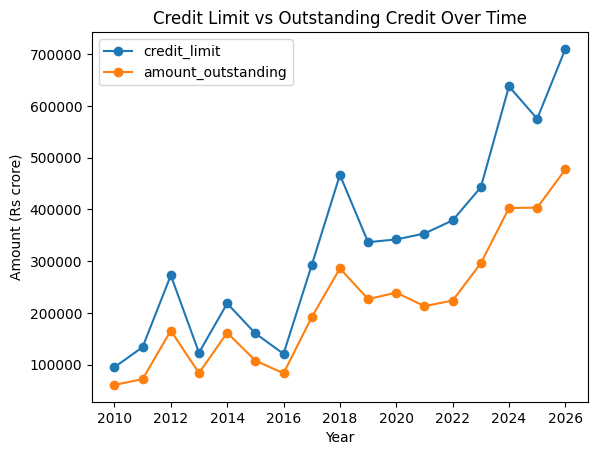

In [ ]:
df.groupby('year')[['credit_limit', 'amount_outstanding']].sum().plot(kind='line', marker='o')

plt.title('Credit Limit vs Outstanding Credit Over Time')
plt.xlabel('Year')
plt.ylabel('Amount (Rs crore)')
plt.show()

**Outstanding Credit by Population Group, 2010-2026**

Metropolitan areas have the highest outstanding credit among rural, semi-urban, urban and metropolitan areas, while the other groups remain well below. Metropolitan credit fluctuated over time.

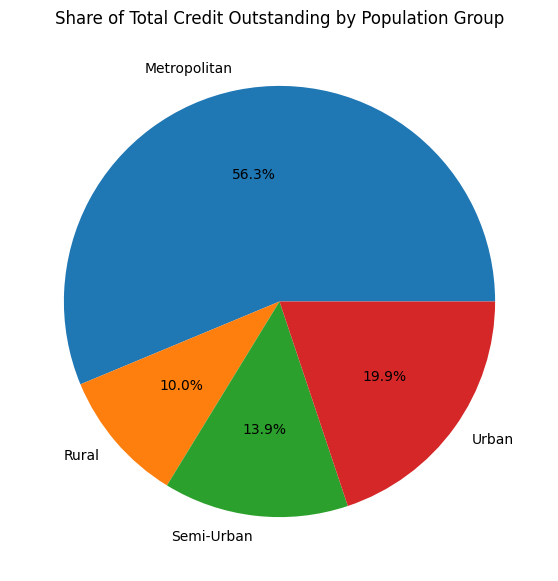

In [ ]:
df.groupby('population_group')['amount_outstanding'].sum().plot(kind='pie', autopct='%1.1f%%', figsize=(7,7))
plt.title('Share of Total Credit Outstanding by Population Group')
plt.ylabel('')
plt.show()

**Outstanding Credit by Region**

The bar chart compares total outstanding credit across six regions. The Southern Region records the highest outstanding credit, followed by the Northern and Western regions. The Central and Eastern regions have lower totals, while the North Eastern Region records the lowest. These differences indicate that outstanding credit is unevenly distributed across the regions covered by the dataset.

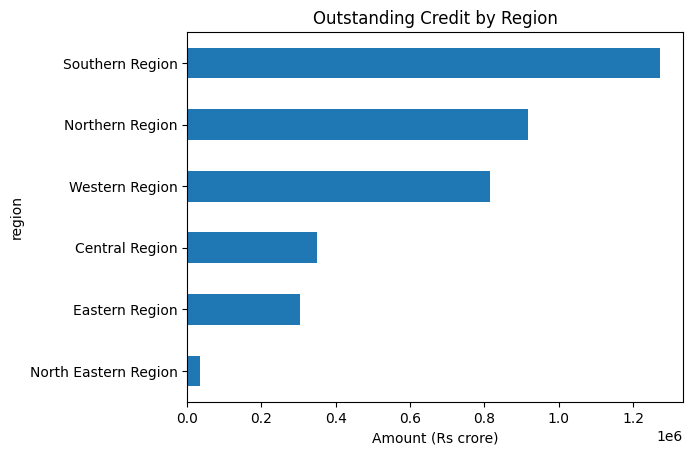

In [ ]:
df.groupby('region')['amount_outstanding'].sum().sort_values().plot(kind='barh')

plt.title('Outstanding Credit by Region')
plt.xlabel('Amount (Rs crore)')
plt.show()

**Credit Share by Occupation Group: 2010 vs 2026**

Industry had the largest share of outstanding credit in 2010, while Personal Loans became the largest in 2026. Finance gained a considerable share, Industry and All Others declined substantially, and Agriculture fell only slightly. Together, these changes show a clear shift in how credit is distributed across occupation groups.

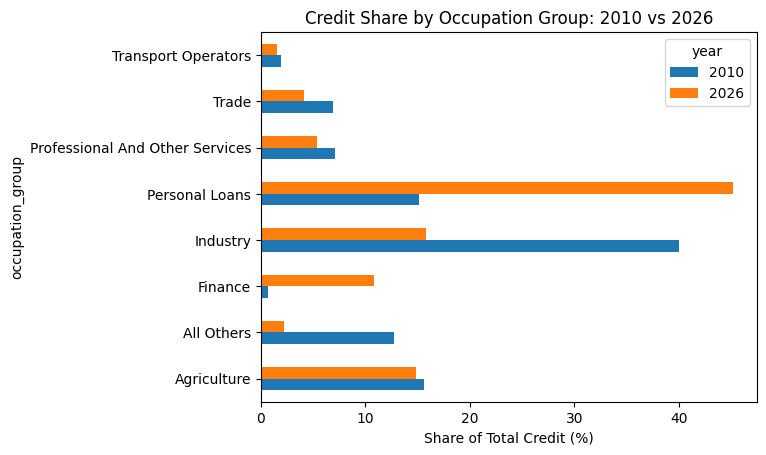

In [ ]:
sector = df[df['year'].isin([2010, 2026])].groupby(['occupation_group', 'year'])['amount_outstanding'].sum().unstack()

sector = sector / sector.sum() * 100

sector.plot(kind='barh')

plt.title('Credit Share by Occupation Group: 2010 vs 2026')
plt.xlabel('Share of Total Credit (%)')
plt.show()

**Average Credit per Account by Population Group**

Metropolitan areas have the highest average outstanding credit per account, followed by urban and semi-urban areas, with rural areas the lowest. Average credit exposure clearly differs across population groups.

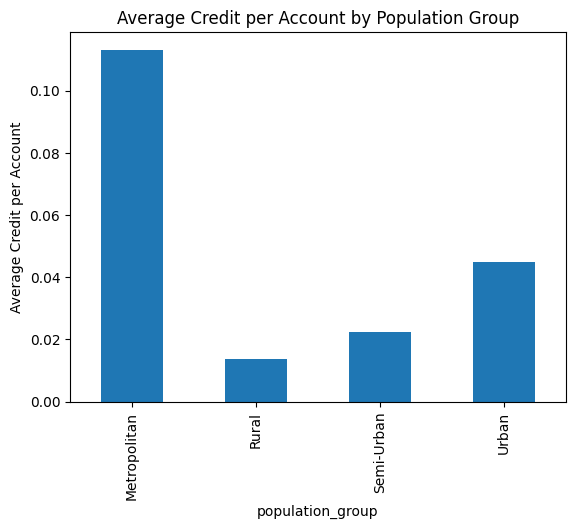

In [ ]:
credit = df.groupby('population_group')['amount_outstanding'].sum()
accounts = df.groupby('population_group')['no_of_accounts'].sum()

(credit / accounts).plot(kind='bar')

plt.title('Average Credit per Account by Population Group')
plt.ylabel('Average Credit per Account')
plt.show()

**Top 10 States by Outstanding Credit**

The bar chart compares the ten states with the highest total outstanding credit. Maharashtra records the highest outstanding credit among these states, while Andhra Pradesh records the lowest within the selected top ten. The chart highlights differences in the distribution of outstanding credit across the leading states.

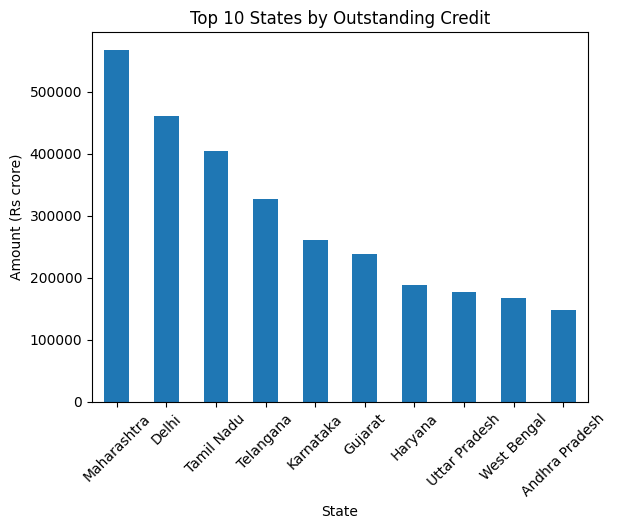

In [ ]:
df.groupby('state_name')['amount_outstanding'].sum().sort_values(ascending=False).head(10).plot(kind='bar')

plt.title('Top 10 States by Outstanding Credit')
plt.xlabel('State')
plt.ylabel('Amount (Rs crore)')
plt.xticks(rotation=45)
plt.show()

 Market Share and Credit Utilization of Bank Groups

The left chart shows that Public Sector Banks (57.5%) and Private Sector Banks (34.8%) dominate credit, while Foreign, Regional Rural and Small Finance Banks together hold under 8%. The right chart shows that utilization is highest for Regional Rural Banks (0.80) and lowest for Foreign Banks (0.53). The banks with the largest market share are therefore not the ones that draw the highest share of their sanctioned limits.

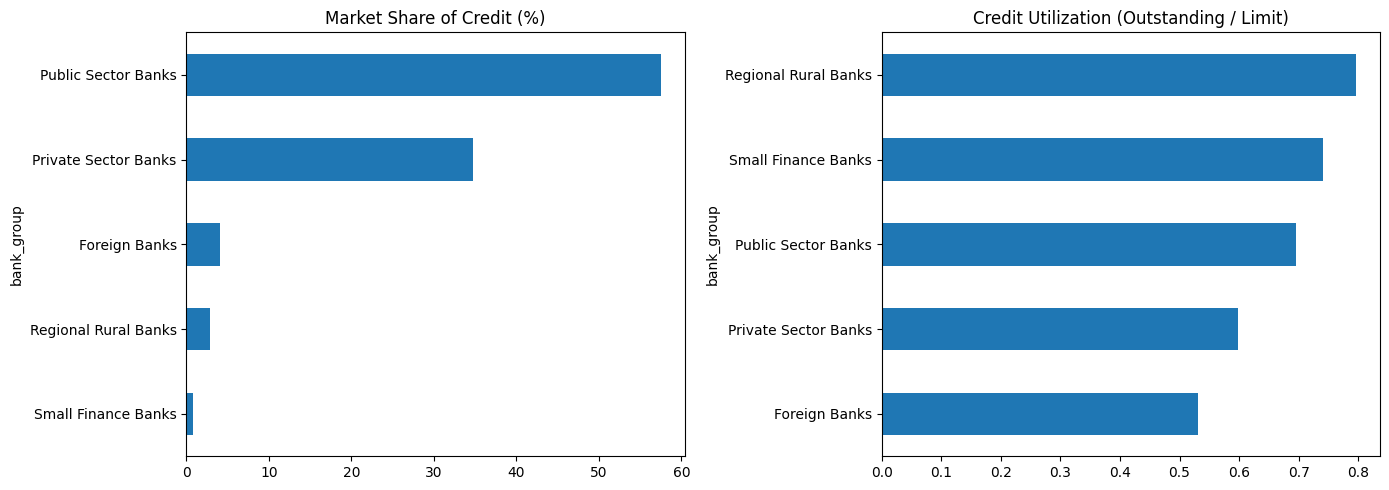

In [ ]:
bank_credit = df.groupby('bank_group')['amount_outstanding'].sum().sort_values(ascending=False).head(5)
bank_limit = df.groupby('bank_group')['credit_limit'].sum().sort_values(ascending=False).head(5)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
(bank_credit / bank_credit.sum() * 100).sort_values().plot(kind='barh', ax=axes[0], title='Market Share of Credit (%)')
(bank_credit / bank_limit).sort_values().plot(kind='barh', ax=axes[1], title='Credit Utilization (Outstanding / Limit)')
plt.tight_layout()
plt.show()

Credit outstanding by occupation group and sub-group (interactive treemap)

Housing loans under Personal Loans are the largest block (13.5% of all credit), followed by Direct Finance under Agriculture (12.6%). Industry is spread across many parts, led by Construction (7.1%).

In [ ]:
import plotly.express as px

fig = px.treemap(df, path=['occupation_group', 'occupation_sub_group'], values='amount_outstanding',
                 title='Credit Outstanding by Occupation Group and Sub-Group')
fig.show()

Industry has a higher share in several early years, but its share declines by 2026. Personal Loans show a lower share during 2010–2020 and a higher share from 2021 onwards. The year-to-year fluctuations may be due to a few large records having a significant influence on the yearly totals.

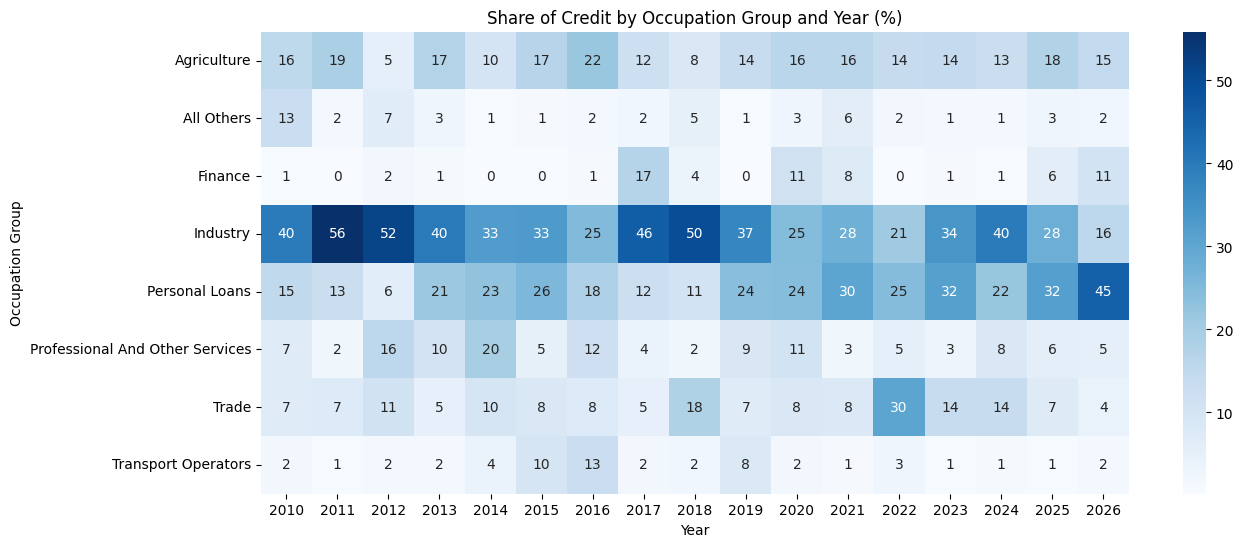

In [ ]:
sector_year = df.groupby(['occupation_group','year'])['amount_outstanding'].sum().unstack()
sector_share = sector_year / sector_year.sum() * 100

plt.figure(figsize=(14, 6))
sns.heatmap(sector_share, annot=True, fmt='.0f', cmap='Blues')
plt.title('Share of Credit by Occupation Group and Year (%)')
plt.xlabel('Year')
plt.ylabel('Occupation Group')
plt.show()